# Datos: tipos, recolección y preparación

Los datos son la materia prima del aprendizaje automático, y su calidad limita la de cualquier modelo. Buena parte del tiempo de un proyecto, a menudo más de la mitad, se dedica a recolectarlos, limpiarlos y transformarlos. Este capítulo resume los tipos de datos, las fuentes más comunes y los pasos básicos de preparación {cite}`kuhn2013,muller2016`.

## Tipos y estructuras de datos

Las variables pueden ser numéricas continuas (pendiente, resistencia, caudal), numéricas discretas (número de sismos en un mes), categóricas nominales (litología, cobertura) o categóricas ordinales (grado de meteorización, de I a VI). La estructura del conjunto también importa. En los datos de corte transversal cada fila es una unidad observada en un mismo momento y las filas no tienen un orden natural, como las celdas de un mapa de susceptibilidad. En las series de tiempo las observaciones tienen un orden cronológico y suelen estar autocorrelacionadas, como la lluvia diaria de una estación. Los datos de panel o longitudinales combinan ambos, como la humedad de varias laderas medida cada semana. En geociencias se suma la dimensión espacial: observaciones cercanas tienden a parecerse más que las lejanas, y eso tiene consecuencias importantes para la validación, como se verá en el capítulo {doc}`06_Validacion`.

## Fuentes de datos

Los datos se obtienen de mediciones de campo y laboratorio, de sensores remotos, de redes de monitoreo, de bases de datos institucionales (el Servicio Geológico Colombiano, el IDEAM o el IGAC), de interfaces de programación de aplicaciones (API), que permiten consultar servicios web desde un programa, y del web scraping, la extracción automática de información de páginas web. Cualquiera que sea la fuente, conviene documentar su origen, fecha, resolución, unidades y limitaciones, porque esa información condiciona qué preguntas se pueden responder.

## Limpieza

El mundo es imperfecto, y los datos también. Los problemas más comunes son los valores faltantes, los valores atípicos, los errores de digitación y unidades, los duplicados y las inconsistencias de formato. La celda siguiente construye un pequeño inventario de deslizamientos con estos problemas para tratarlos uno a uno con `pandas`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(3)

n = 300
df = pd.DataFrame({
    'pendiente': rng.gamma(4, 6, n).round(1),
    'lluvia_mm': rng.normal(2500, 500, n).round(0),
    'dist_cauce_m': rng.exponential(250, n).round(0),
    'litologia': rng.choice(['granito', 'esquisto', 'lutita', 'Lutita ', 'GRANITO'], n, p=[0.35, 0.3, 0.25, 0.05, 0.05]),
})
df.loc[rng.choice(n, 25, replace=False), 'lluvia_mm'] = np.nan          # faltantes
df.loc[rng.choice(n, 4, replace=False), 'pendiente'] = [95, 120, -5, 88]  # errores: pendientes imposibles
df.loc[rng.choice(n, 3, replace=False), 'dist_cauce_m'] = 25000           # atípicos (¿en metros o en otra unidad?)
df = pd.concat([df, df.iloc[:5]], ignore_index=True)                       # duplicados
print(df.describe(include='all').round(1))
print('\nFaltantes por columna:'); print(df.isna().sum())
print('\nCategorías de litología:', df['litologia'].unique())

        pendiente  lluvia_mm  dist_cauce_m litologia
count       305.0      279.0         305.0       305
unique        NaN        NaN           NaN         5
top           NaN        NaN           NaN   granito
freq          NaN        NaN           NaN       111
mean         26.7     2468.6         496.1       NaN
std          15.3      501.8        2458.0       NaN
min          -5.0     1002.0           3.0       NaN
25%          17.3     2118.0          69.0       NaN
50%          23.8     2476.0         190.0       NaN
75%          32.4     2830.5         368.0       NaN
max         120.0     3786.0       25000.0       NaN

Faltantes por columna:
pendiente        0
lluvia_mm       26
dist_cauce_m     0
litologia        0
dtype: int64

Categorías de litología: <StringArray>
['lutita', 'granito', 'esquisto', 'Lutita ', 'GRANITO']
Length: 5, dtype: str


In [2]:
limpio = df.drop_duplicates().copy()
limpio['litologia'] = limpio['litologia'].str.strip().str.lower()         # homogeneizar categorías
fuera = ~limpio['pendiente'].between(0, 90)
print(f'Pendientes físicamente imposibles: {fuera.sum()}')
limpio.loc[fuera, 'pendiente'] = np.nan
print('Filas después de quitar duplicados:', len(limpio))
print('Categorías:', limpio['litologia'].unique())

Pendientes físicamente imposibles: 3
Filas después de quitar duplicados: 300
Categorías: <StringArray>
['lutita', 'granito', 'esquisto']
Length: 3, dtype: str


## Valores atípicos

Un valor atípico es una observación que se aleja mucho del resto. Puede ser un error, que hay que corregir o eliminar, o un dato real y valioso, como un evento extremo, que hay que conservar. La regla del diagrama de caja marca como atípicos moderados los valores a más de 1.5 veces el rango intercuartílico (RIC) por fuera del primer o tercer cuartil, y como extremos los que están a más de 3 RIC. Para variables asimétricas, como la distancia a los cauces, conviene aplicar la regla sobre la variable transformada con un logaritmo.

Atípicos en la variable original: 14
Atípicos en log(distancia): 4 -> [2.5e+04 2.5e+04 3.0e+00 2.5e+04]


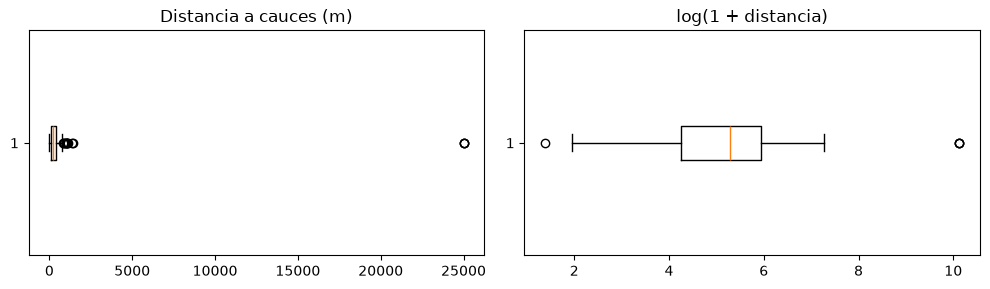

In [3]:
def atipicos_ric(x, k=1.5):
    q1, q3 = np.nanpercentile(x, [25, 75])
    ric = q3 - q1
    return (x < q1 - k * ric) | (x > q3 + k * ric)

d = limpio['dist_cauce_m']
print('Atípicos en la variable original:', atipicos_ric(d).sum())
print('Atípicos en log(distancia):', atipicos_ric(np.log1p(d)).sum(), '->', d[atipicos_ric(np.log1p(d))].values)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].boxplot(d.dropna(), orientation='horizontal'); ax[0].set_title('Distancia a cauces (m)')
ax[1].boxplot(np.log1p(d.dropna()), orientation='horizontal'); ax[1].set_title('log(1 + distancia)')
plt.tight_layout(); plt.show()

Los tres valores de 25 000 m siguen siendo atípicos en escala logarítmica y no son plausibles en una cuenca pequeña: probablemente se digitaron en otra unidad. Lo correcto es revisar la fuente; si no es posible, se tratan como faltantes. La regla también marca una distancia muy pequeña, de pocos metros, que es perfectamente posible (un sitio junto al cauce) y se conserva: ninguna regla automática reemplaza el criterio del analista.

## Valores faltantes e imputación

Los valores faltantes pueden eliminarse (perdiendo filas o columnas) o imputarse. La imputación con la media o la mediana es simple pero reduce la variabilidad y debilita las correlaciones; la imputación por vecinos más cercanos o por regresión usa la información de las demás variables. Lo más importante es entender por qué faltan los datos: si faltan al azar, cualquier método razonable funciona; si faltan por una razón relacionada con la respuesta (por ejemplo, porque las estaciones de lluvia fallan durante las tormentas), imputar puede sesgar el modelo. La celda siguiente compara la imputación por mediana y por vecinos más cercanos en un caso en que la lluvia depende de la elevación.

In [4]:
from sklearn.impute import SimpleImputer, KNNImputer
elev = rng.uniform(800, 3000, 500)
lluvia = 1200 + 0.7 * elev + rng.normal(0, 150, 500)
faltan = rng.random(500) < 0.2
datos = np.column_stack([elev, np.where(faltan, np.nan, lluvia)])
for nombre, imp in [('mediana', SimpleImputer(strategy='median')), ('vecinos (k=5)', KNNImputer(n_neighbors=5))]:
    est = imp.fit_transform(datos)[faltan, 1]
    print(f'Imputación por {nombre:14s}: error medio absoluto {np.abs(est - lluvia[faltan]).mean():6.1f} mm')

Imputación por mediana       : error medio absoluto  396.4 mm
Imputación por vecinos (k=5) : error medio absoluto  130.8 mm


## Transformación, escalado y codificación

Muchos métodos no son invariantes a la escala: los basados en distancias (vecinos más cercanos, agrupamiento, máquinas de soporte vectorial), los regularizados y las redes neuronales dan más peso a las variables con valores más grandes. Por eso se escalan las variables. La estandarización resta la media y divide por la desviación estándar; la normalización min-max lleva cada variable al intervalo [0, 1]; el escalado robusto usa la mediana y el rango intercuartílico y es menos sensible a los atípicos. Las variables muy asimétricas, como distancias, áreas o concentraciones, suelen mejorar con una transformación logarítmica (que exige valores positivos). Las variables categóricas nominales se codifican con variables indicadoras (one-hot), una columna binaria por categoría; las ordinales pueden codificarse con enteros que respeten el orden.

Una regla esencial: los parámetros de cualquier transformación (la media, la desviación, las categorías) se calculan solo con los datos de entrenamiento y luego se aplican a los de prueba. Calcularlos con todos los datos filtra información del conjunto de prueba al entrenamiento (fuga de datos) y produce evaluaciones optimistas. En `scikit-learn` la forma segura de hacerlo es encadenar la preparación y el modelo en un `Pipeline`.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline, make_pipeline

limpio.loc[limpio['dist_cauce_m'] > 5000, 'dist_cauce_m'] = np.nan
num = ['pendiente', 'lluvia_mm', 'dist_cauce_m']
prep = ColumnTransformer([
    ('num_log', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p, feature_names_out='one-to-one'), StandardScaler()), ['dist_cauce_m']),
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), ['pendiente', 'lluvia_mm']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['litologia']),
])
Xp = prep.fit_transform(limpio)
print('Forma de la matriz preparada:', Xp.shape)
print('Columnas:', list(prep.get_feature_names_out()))
print('Medias de las columnas numéricas (≈0):', Xp[:, :3].mean(axis=0).round(3))

Forma de la matriz preparada: (300, 6)
Columnas: ['num_log__dist_cauce_m', 'num__pendiente', 'num__lluvia_mm', 'cat__litologia_esquisto', 'cat__litologia_granito', 'cat__litologia_lutita']
Medias de las columnas numéricas (≈0): [-0. -0. -0.]


## Ingeniería de variables

La ingeniería de variables (feature engineering) transforma los datos crudos en variables que representan mejor el problema. En geociencias suele ser donde más se gana: derivar del modelo de elevación la pendiente, la curvatura, el área de drenaje o el índice topográfico de humedad; calcular la lluvia antecedente de 3, 7 o 30 días; combinar bandas en índices espectrales. Es un proceso iterativo de agregar, quitar y cambiar variables, guiado por el conocimiento del dominio, que es la mejor defensa contra los modelos que aprenden correlaciones espurias.

## Para profundizar

Los capítulos 3 y 4 de {cite}`kuhn2013` tratan la preparación de datos con detalle. El capítulo 4 de {cite}`muller2016` muestra la representación de variables y los `Pipeline` de `scikit-learn`. Los notebooks 02 a 04 del curso aplican estos pasos a datos reales.